In [1]:
import pandas as pd
from pipeline import IndicatorSpec, build_feature_df
from data import fetch_binance_klines
from simulation.rules import Rule, RuleGroup, ALL, ANY
from simulation.rule_features import add_last_n_compare, add_cross_compare
from simulation.simulator import Strategy, SimConfig, run_simulation, align_timeframes
from plot_simulation import plot_simulation
from plotter import plot_interactive, PlotConfig, IndicatorSpec
from mtf_plot import make_plot_indicators, assert_plot_columns_exist
from features.ema_spreads import EmaSpreadSpec, add_ema_spread_features
from features.cross_through import CrossThroughSpec, add_cross_through_features
from features.stochastic_signals import add_stochastic_signal_features
from simulation.rules import Ctx
from analytics import (
    trades_to_frame,
    plot_balance_by_trade,
    plot_trade_pnl_bars,
    trade_summary_table
)
from plot_toggles import (
    PlotToggle,
    make_plot_indicators_from_toggles,
    assert_plot_columns_exist,
)

from ema_diagnostic_plots import (
    ema_pair_spread_panel,
    ema_group_spread_panel,
    ema_cut_through_panel,
)
from simulation.simulator import (
    TradeExitConfig,
    StopLossConfig,
    PositionSizingConfig,
    TakeProfitConfig,
)

In [2]:
symbol = "BTCUSDT"
market = "spot"
tz = "Asia/Karachi"

# Start earlier for EMA warmup.
fetch_start = "2025-11-01"
sim_start = "2026-05-06"
end = None

In [3]:
# ============================================================
# STOCHASTIC Configs
# ============================================================

STOCH_CFG = {
    "k_length": 14,
    "d_length": 3,
    "smooth": 3,
}

In [4]:
### 1 Minute Indicators ###
EMA50_1m = "1m__ema__EMA_50"
EMA100_1m = "1m__ema__EMA_100"
EMA150_1m = "1m__ema__EMA_150"
EMA200_1m = "1m__ema__EMA_200"
MACD_1M = "1m__macd_8_21_5__MACD"
MACD_SIGNAL_1M = "1m__macd_8_21_5__SIGNAL"
MACD_HIST_1M = "1m__macd_8_21_5__HIST"
BULL_DIV_1m = "1m__rsi14__BULL_DIV"
BEAR_DIV_1m = "1m__rsi14__BEAR_DIV"
BULL_START_RSI_1m = "1m__rsi14__BULL_START_RSI"
BEAR_START_RSI_1m = "1m__rsi14__BEAR_START_RSI"
STO_K_1M = "1m__st14__K"
STO_D_1M = "1m__st14__D"
STO_1M_UP20_ACTIVE_5 = "1m__st14__K_CROSS_UP_20_ACTIVE_5"
STO_1M_DOWN20_ACTIVE_5 = "1m__st14__K_CROSS_DOWN_20_ACTIVE_5"

### 5 Minute Indicators ###
EMA50_5m = "5m__ema__EMA_50"
EMA75_5m = "5m__ema__EMA_75"
EMA100_5m = "5m__ema__EMA_100"
EMA125_5m = "5m__ema__EMA_125"
EMA150_5m = "5m__ema__EMA_150"
EMA175_5m = "5m__ema__EMA_175"
EMA200_5m = "5m__ema__EMA_200"
MACD_5M = "5m__macd_8_21_5__MACD"
MACD_SIGNAL_5M = "5m__macd_8_21_5__SIGNAL"
MACD_HIST_5M = "5m__macd_8_21_5__HIST"
BULL_DIV_5m = "5m__rsi14__BULL_DIV"
BEAR_DIV_5m = "5m__rsi14__BEAR_DIV"
BULL_START_RSI_5m = "5m__rsi14__BULL_START_RSI"
BEAR_START_RSI_5m = "5m__rsi14__BEAR_START_RSI"
STO_K_5M = "5m__st14__K"
STO_D_5M = "5m__st14__D"
STO_5M_UP20_ACTIVE_3 = "5m__st14__K_CROSS_UP_20_ACTIVE_3"
STO_5M_DOWN20_ACTIVE_3 = "5m__st14__K_CROSS_DOWN_20_ACTIVE_3"


### 15 Minute Indicators ###
EMA50_15m = "15m__ema__EMA_50"
EMA75_15m = "15m__ema__EMA_75"
EMA100_15m = "15m__ema__EMA_100"
EMA125_15m = "15m__ema__EMA_125"
EMA150_15m = "15m__ema__EMA_150"
EMA175_15m = "15m__ema__EMA_175"
EMA200_15m = "15m__ema__EMA_200"
MACD_15M = "15m__macd_8_21_5__MACD"
MACD_SIGNAL_15M = "15m__macd_8_21_5__SIGNAL"
MACD_HIST_15M = "15m__macd_8_21_5__HIST"
BULL_DIV_15m = "15m__rsi14__BULL_DIV"
BEAR_DIV_15m = "15m__rsi14__BEAR_DIV"
BULL_START_RSI_15m = "15m__rsi14__BULL_START_RSI"
BEAR_START_RSI_15m = "15m__rsi14__BEAR_START_RSI"
STO_K_15M = "15m__st14__K"
STO_D_15M = "15m__st14__D"
STO_15M_UP20_ACTIVE_3 = "15m__st14__K_CROSS_UP_20_ACTIVE_3"
STO_15M_DOWN20_ACTIVE_3 = "15m__st14__K_CROSS_DOWN_20_ACTIVE_3"

### 1 Hour Indicators ###
EMA50_1h = "1h__ema__EMA_50"
EMA75_1h = "1h__ema__EMA_75"
EMA100_1h = "1h__ema__EMA_100"
EMA125_1h = "1h__ema__EMA_125"
EMA150_1h = "1h__ema__EMA_150"
EMA175_1h = "1h__ema__EMA_175"
EMA200_1h = "1h__ema__EMA_200"
MACD_1H = "1h__macd_8_21_5__MACD"
MACD_SIGNAL_1H = "1h__macd_8_21_5__SIGNAL"
MACD_HIST_1H = "1h__macd_8_21_5__HIST"
BULL_DIV_1h = "1h__rsi14__BULL_DIV"
BEAR_DIV_1h = "1h__rsi14__BEAR_DIV"
BULL_START_RSI_1h = "1h__rsi14__BULL_START_RSI"
BEAR_START_RSI_1h = "1h__rsi14__BEAR_START_RSI"
STO_K_1H = "1h__st14__K"
STO_D_1H = "1h__st14__D"
STO_1H_UP20_ACTIVE_3 = "1h__st14__K_CROSS_UP_20_ACTIVE_3"
STO_1H_DOWN20_ACTIVE_3 = "1h__st14__K_CROSS_DOWN_20_ACTIVE_3"

In [5]:
# ============================================================
# 1m indicators
# ============================================================

ind_1m = [
    IndicatorSpec("moving_average", tag="ema", config={
        "type": "ema",
        "periods": [50, 100, 150, 200, 250],
        "source": "close",
    }),

    IndicatorSpec("macd", tag="macd_8_21_5", config={
        "fast": 8,
        "slow": 21,
        "signal": 5,
    }),

    IndicatorSpec("stochastic", tag="st14", config=STOCH_CFG),
]


# ============================================================
# 5m indicators
# ============================================================

ind_5m = [
    IndicatorSpec("moving_average", tag="ema", config={
        "type": "ema",
        "periods": [50, 75, 100, 125, 150, 175, 200],
        "source": "close",
    }),

    IndicatorSpec("macd", tag="macd_8_21_5", config={
        "fast": 8,
        "slow": 21,
        "signal": 5,
    }),

    IndicatorSpec("stochastic", tag="st14", config=STOCH_CFG),
]


# ============================================================
# 15m indicators
# ============================================================

ind_15m = [
    IndicatorSpec("moving_average", tag="ema", config={
        "type": "ema",
        "periods": [50, 75, 100, 125, 150, 175, 200],
        "source": "close",
    }),

    IndicatorSpec("macd", tag="macd_8_21_5", config={
        "fast": 8,
        "slow": 21,
        "signal": 5,
    }),

    IndicatorSpec("stochastic", tag="st14", config=STOCH_CFG),
]

# ============================================================
# 1h indicators
# ============================================================

ind_1h = [
    IndicatorSpec("moving_average", tag="ema", config={
        "type": "ema",
        "periods": [50, 75, 100, 125, 150, 175, 200],
        "source": "close",
    }),

    IndicatorSpec("macd", tag="macd_8_21_5", config={
        "fast": 8,
        "slow": 21,
        "signal": 5,
    }),

    IndicatorSpec("stochastic", tag="st14", config=STOCH_CFG),
]

In [6]:
# 1m base data
df1 = fetch_binance_klines(
    symbol=symbol,
    interval="1m",
    start=fetch_start,
    end=end,
    market=market,
    cache=True,
    cache_dir="data",
)

df1_feat, _, _ = build_feature_df(
    raw_df=df1,
    tz=tz,
    ma_windows=[],
    indicators=ind_1m,
)


# 5m filter data
df5 = fetch_binance_klines(
    symbol=symbol,
    interval="5m",
    start=fetch_start,
    end=end,
    market=market,
    cache=True,
    cache_dir="data",
)

df5_feat, _, _ = build_feature_df(
    raw_df=df5,
    tz=tz,
    ma_windows=[],
    indicators=ind_5m,
)


# 15m filter data
df15 = fetch_binance_klines(
    symbol=symbol,
    interval="15m",
    start=fetch_start,
    end=end,
    market=market,
    cache=True,
    cache_dir="data",
)

df15_feat, _, _ = build_feature_df(
    raw_df=df15,
    tz=tz,
    ma_windows=[],
    indicators=ind_15m,
)

# 1h filter data
df60 = fetch_binance_klines(
    symbol=symbol,
    interval="1h",
    start=fetch_start,
    end=end,
    market=market,
    cache=True,
    cache_dir="data",
)

df60_feat, _, _ = build_feature_df(
    raw_df=df60,
    tz=tz,
    ma_windows=[],
    indicators=ind_1h,
)


# Add Stochastic Features
df1_feat = add_stochastic_signal_features(
    df1_feat,
    tag="st14",
    levels=(10, 20, 30),
    windows=(1, 2, 3, 5),
    source="K",
)

df5_feat = add_stochastic_signal_features(
    df5_feat,
    tag="st14",
    levels=(10, 20, 30),
    windows=(1,2, 3, 5, 6),
    source="K",
)

df15_feat = add_stochastic_signal_features(
    df15_feat,
    tag="st14",
    levels=(10, 20, 30),
    windows=(1, 2, 3, 5),
    source="K",
)

df60_feat = add_stochastic_signal_features(
    df60_feat,
    tag="st14",
    levels=(10, 20, 30),
    windows=(1, 2),
    source="K",
)

merged = align_timeframes(
    base_df=df1_feat,
    other_dfs={
        "5m": df5_feat,
        "15m": df15_feat,
        "1h": df60_feat,
    },
    base_label="1m",
)


[17:50:35] INFO | 01. Parameters: market=spot, symbol=BTCUSDT, interval=1m, start=2025-11-01 00:00:00+00:00, end=LATEST
[17:50:35] INFO | 02. Cache directory: C:\Users\Talal Zahid\Desktop\Talal\Binance\data (cwd=C:\Users\Talal Zahid\Desktop\Talal\Binance)
[17:50:35] INFO | 03. Main cache file: C:\Users\Talal Zahid\Desktop\Talal\Binance\data\binance_spot_BTCUSDT_1m.parquet
[17:50:35] INFO | 04. Partial checkpoint dir: C:\Users\Talal Zahid\Desktop\Talal\Binance\data\.partials\binance_spot_BTCUSDT_1m
[17:50:36] INFO | 05. Cache: HIT | rows=294,528 (main_rows=294,528, partial_files=0) | range=2025-11-01 00:00:00+00:00 -> 2026-05-24 12:47:00+00:00
[17:50:36] INFO | 06. Fetch plan 1/1: 2026-05-24 12:48:00+00:00 -> LATEST
[17:50:36] INFO | 07. Starting fetch range 1/1.


BTCUSDT 1m: 0page [00:00, ?page/s]

[17:50:36] INFO | 08. Completed fetch range 1/1 | rows=3 | total_rows_fetched=3 | requests=1 | retries=0 | elapsed=1.0s
[17:50:37] INFO | 09. Cache consolidated and saved (parquet) | rows=294,531 | range=2025-11-01 00:00:00+00:00 -> 2026-05-24 12:50:00+00:00 | cleared_partial_files=1
[17:50:37] INFO | 10. Fetch summary | new_rows=3 | successful_pages=1 | requests=1 | retries=0 | partial_saves=1 | elapsed=1.4s
[17:50:37] INFO | 11. Returning slice | rows=294,531 | range=2025-11-01 00:00:00+00:00 -> 2026-05-24 12:50:00+00:00
[17:50:37] INFO | 01. Parameters: market=spot, symbol=BTCUSDT, interval=5m, start=2025-11-01 00:00:00+00:00, end=LATEST
[17:50:37] INFO | 02. Cache directory: C:\Users\Talal Zahid\Desktop\Talal\Binance\data (cwd=C:\Users\Talal Zahid\Desktop\Talal\Binance)
[17:50:37] INFO | 03. Main cache file: C:\Users\Talal Zahid\Desktop\Talal\Binance\data\binance_spot_BTCUSDT_5m.parquet
[17:50:37] INFO | 04. Partial checkpoint dir: C:\Users\Talal Zahid\Desktop\Talal\Binance\data\.p

In [7]:
N_CONFIRM = 1               # number of consecutive confirmation candles required
MAX_WAIT_AFTER_CROSS = 30   # how many candles after the cross we are willing to wait
MACD_THRESHOLD_1M = 100
MACD_THRESHOLD_5M = 10
MACD_THRESHOLD_15M = 10 

MIN_MACD_DIFF_1M = 5
MIN_MACD_DIFF_5M = 5
MIN_MACD_DIFF_15M = 5

DIV_LOOKBACK = 5

N_SPREAD_CONFIRM = 3
MIN_SPREAD_PCT = 0.1

MIN_EMAS_CROSSED = 4
CROSS_LOOKBACK = 40


#####################################################################################


LONG_EMA_FILTERS = [
    # EMA50_1m,
    EMA100_1m,
    # EMA150_1m,
    # EMA200_1m,
    # EMA100_5m,
    # EMA200_5m,
    # EMA100_15m,
    #EMA200_15m
]


macd_rules = ALL(
    Rule(
        "1m MACD above threshold",
        lambda c: c.gt(MACD_1M, 10)
    ),
    
    # Rule(
    #     "5m MACD above threshold",
    #     lambda c: c.gt(MACD_5M, MACD_THRESHOLD_5M)
    # ),
    
    # Rule(
    #     "15m MACD above threshold",
    #     lambda c: c.gt(MACD_15M, MACD_THRESHOLD_15M)
    # ),

    Rule(
        "1m MACD - Signal above minimum",
        lambda c: c.gt(MACD_HIST_1M, 50)
    ),
    
    Rule(
         "5m MACD - Signal above minimum",
         lambda c: c.gt(MACD_HIST_5M, 20)
     ),

    Rule(
        "15m MACD - Signal above minimum",
        lambda c: c.gt(MACD_HIST_15M, 20)
    ),
    
)


open_rules_long = ALL(
    macd_rules,
    Rule(
        "Current close above all EMA filters",
        lambda c: c.close_below_all(LONG_EMA_FILTERS)

),
    Rule(
        f"Last {N_CONFIRM} candles green",
        lambda c: c.consecutive_green(n=N_CONFIRM)
    ),
)



close_rules_long = ALL(
    Rule(
        "Current close above all EMA filters",
        lambda c: c.close_below_all(LONG_EMA_FILTERS)

),
)




###################### stochastic  rules #########################


X_1M = 5
Y_5M = 6
Z_15M = 3

open_rules_long_stoch_recovery = ALL(

    Rule(
        "1m MACD above threshold",
        lambda c: c.gt(MACD_1M, 100)
    ),
    
    # Rule(
    #     "5m MACD above threshold",
    #     lambda c: c.gt(MACD_5M, 5)
    # ),
    
    Rule(
        "Current close above all EMA filters",
        lambda c: c.close_above_all(LONG_EMA_FILTERS)

    ),
    # Rule(
    #     "1m MACD - Signal above minimum",
    #     lambda c: c.lt(EMA50_5m, EMA100_5m)
    # ),
    # Rule(
    #     f"1m stochastic K crossed up 20 in last {1} 1m candles and stayed above",
    #     lambda c: c.flag(f"1m__st14__K_CROSS_UP_20_ACTIVE_{1}")
    # ),

    Rule(
        f"5m stochastic K crossed up 20 in last {Y_5M} 5m candles and stayed above",
        lambda c: c.flag(f"5m__st14__K_CROSS_UP_20_ACTIVE_{Y_5M}")
    ),

    Rule(
        "15m Stochastic K > D",
        lambda c: c.gt(STO_K_15M, STO_D_15M)
    ),
    Rule(
        "5m Stochastic K > D",
        lambda c: c.gt(STO_K_5M, STO_D_5M)
    ),
    # Rule(
    #     f"15m stochastic K crossed up 20 in last {Z_15M} 15m candles and stayed above",
    #     lambda c: c.flag(f"15m__st14__K_CROSS_UP_20_ACTIVE_{Z_15M}")
    # ),
    Rule(
        f"1m stochastic K crossed up 20 in last {1} 1m candles and stayed above",
        lambda c: c.flag(f"1h__st14__K_CROSS_UP_20_ACTIVE_{1}")
    )
)

close_rules_long_stoch_recovery = ANY(
    Rule(
        "1m stochastic K crossed back below 20",
        lambda c: c.flag("1m__st14__K_CROSS_DOWN_20")
    ),

    Rule(
        "1m stochastic K crossed down from overbought 80",
        lambda c: c.flag("1m__st14__K_CROSS_DOWN_80")
    ),
)

In [8]:
strategy = Strategy(
    open_rules_long=open_rules_long_stoch_recovery,
    close_rules_long=close_rules_long_stoch_recovery,
)

cfg = SimConfig(
    initial_cash=10_000,
    max_open_trades=1,
    fee_bps=10,
    slippage_bps=1,

    sim_start="2025-11-01",
    sim_end="2026-05-25",
    sim_tz=tz,

    exit=TradeExitConfig(
        enabled=True,
        # Important:
        # if both TP and SL are touched in same candle, assume SL first
        intrabar_priority="stop_first",
        # Important:
        # disables ST2 close rule while TP/SL system is active
        allow_rule_close=False,
        
        # stop_loss=StopLossConfig(
        #     mode="entry_pct",
        #     value=1,   # 0.5% below entry for long
        # ),

        # sizing=PositionSizingConfig(
        #     mode="cash",  # use normal full cash sizing
        # ),

        # take_profits=(
        #     TakeProfitConfig(
        #         label="TP1",
        #         mode="entry_pct",
        #         value=2,       # +1.0%
        #         close_pct=100.0, # close full trade
        #     ),
        # ),
        stop_loss=StopLossConfig(
            mode="entry_pct",
            value=1,   # 0.5% below entry for long
        ),
        sizing=PositionSizingConfig(
            mode="cash",  # use normal full cash sizing
        ),
        take_profits=(
            TakeProfitConfig(
                label="TP1",
                mode="entry_pct",
                value=1,          # +0.5%
                close_pct=100.0,     # close 50% of remaining
                # move_stop_mode="breakeven",
            ),

            # TakeProfitConfig(
            #     label="TP2",
            #     mode="entry_pct",
            #     value=1,          # +1.0%
            #     close_pct=100.0,    # close rest
            # ),
        ),
    ),
)

res = run_simulation(
    df=merged,
    strategy=strategy,
    cfg=cfg,
    time_col="t",
    price_col="close",
)

res.stats #, res.events.head(), res.equity_curve.tail()

[17:50:58] INFO | Simulation window applied | rows=294,531/294,531 | range=2025-11-01 05:00:00+05:00 -> 2026-05-24 17:50:00+05:00


Simulation:   0%|          | 0/294531 [00:00<?, ?bar/s]

[17:50:58] INFO | Simulation started | bars=294,531 | initial_cash=10,000.00 | cash_per_trade=10,000.00 | max_open_trades=1 | fee_bps=10 | slippage_bps=1 | exit_enabled=True
[17:51:10] INFO | Simulation finished | elapsed=17.23s | bars=294,531 | opened=5 | closed=5 | final_cash=10,193.38 | total_return=1.93% | max_dd=1.78%


{'initial_cash': 10000.0,
 'final_cash': 10193.382474046639,
 'total_pnl': 193.38247404664077,
 'total_return_pct': 1.9338247404663944,
 'num_trades': 5.0,
 'num_winners': 4.0,
 'num_losers': 1.0,
 'num_breakeven': 0.0,
 'win_rate_pct': 80.0,
 'loss_rate_pct': 20.0,
 'gross_profit': 314.2714840466409,
 'gross_loss': 120.88901000000014,
 'profit_factor': 2.599669598143293,
 'avg_pnl': 38.676494809328155,
 'median_pnl': 78.5521596563224,
 'avg_winner': 78.56787101166023,
 'avg_loser': -120.88901000000014,
 'avg_loser_abs': 120.88901000000014,
 'largest_winner': 78.89101000000015,
 'largest_loser': -120.88901000000014,
 'payoff_ratio': 0.6499173995358233,
 'expectancy_per_trade': 38.676494809328155,
 'expectancy_pct_initial_cash': 0.38676494809328155,
 'avg_return_pct': 0.3893500599999956,
 'median_return_pct': 0.7889100999999944,
 'best_return_pct': 0.7889101000000013,
 'worst_return_pct': -1.2088901000000014,
 'avg_duration_min': 143.6,
 'median_duration_min': 145.0,
 'avg_bars_held': 1

In [9]:
trade_summary_table(res.trades, initial_cash=10_000, interval="1m")

,trade_no,trade_id,side,entry_time,exit_time,entry_price,exit_price,qty,pnl,return_pct,duration_min,candle_count,balance,open_reason,close_reason
1,1,1.0,long,2025-11-14 12:00:00+05:00,2025-11-14 16:19:00+05:00,97419.941020,96436.097036,0.102648,-120.889010,-1.0099,259.0,259.0,9879.110990,"1m MACD above threshold, Current close above a...",STOP_LOSS
2,2,2.0,long,2025-11-24 20:01:00+05:00,2025-11-24 21:02:00+05:00,86201.729311,87055.040229,0.114605,77.937304,0.9899,61.0,61.0,9957.048294,"1m MACD above threshold, Current close above a...",TAKE_PROFIT_FULL
3,3,3.0,long,2026-02-01 01:55:00+05:00,2026-02-01 04:20:00+05:00,77809.880210,78580.120214,0.127966,78.552160,0.9899,145.0,145.0,10035.600454,"1m MACD above threshold, Current close above a...",TAKE_PROFIT_FULL
4,4,4.0,long,2026-02-17 21:00:00+05:00,2026-02-17 21:36:00+05:00,67366.756002,68033.619520,0.148441,78.891010,0.9899,36.0,36.0,10114.491464,"1m MACD above threshold, Current close above a...",TAKE_PROFIT_FULL
5,5,5.0,long,2026-03-20 23:00:00+05:00,2026-03-21 02:37:00+05:00,69964.605761,70657.185393,0.142929,78.891010,0.9899,217.0,217.0,10193.382474,"1m MACD above threshold, Current close above a...",TAKE_PROFIT_FULL


In [10]:
indicators_by_tf = {
    "1m": ind_1m,
    "5m": ind_5m,
    "15m": ind_15m,
    "1h": ind_1h,
}


plot_toggles = [
    # Optional EMA overlays
    PlotToggle("1m", "ema", visible="legendonly"),
    PlotToggle("5m", "ema", visible="legendonly"),
    PlotToggle("15m", "ema", visible="legendonly"),
    PlotToggle("1h", "ema", visible="legendonly"),

    # Stochastic panels
    PlotToggle("1m", "st14", visible="legendonly"),
    PlotToggle("5m", "st14", visible=True),
    PlotToggle("15m", "st14", visible=True),
    PlotToggle("1h", "st14", visible=True),

    # Hide MACD
    PlotToggle("1m", "macd_8_21_5",  visible="legendonly"),
    PlotToggle("5m", "macd_8_21_5",  visible="legendonly"),
    PlotToggle("15m", "macd_8_21_5",  visible="legendonly"),
    PlotToggle("1h", "macd_8_21_5",  visible="legendonly"),

]

plot_indicators = make_plot_indicators_from_toggles(
    indicators_by_tf=indicators_by_tf,
    toggles=plot_toggles,
)

assert_plot_columns_exist(merged, plot_indicators)


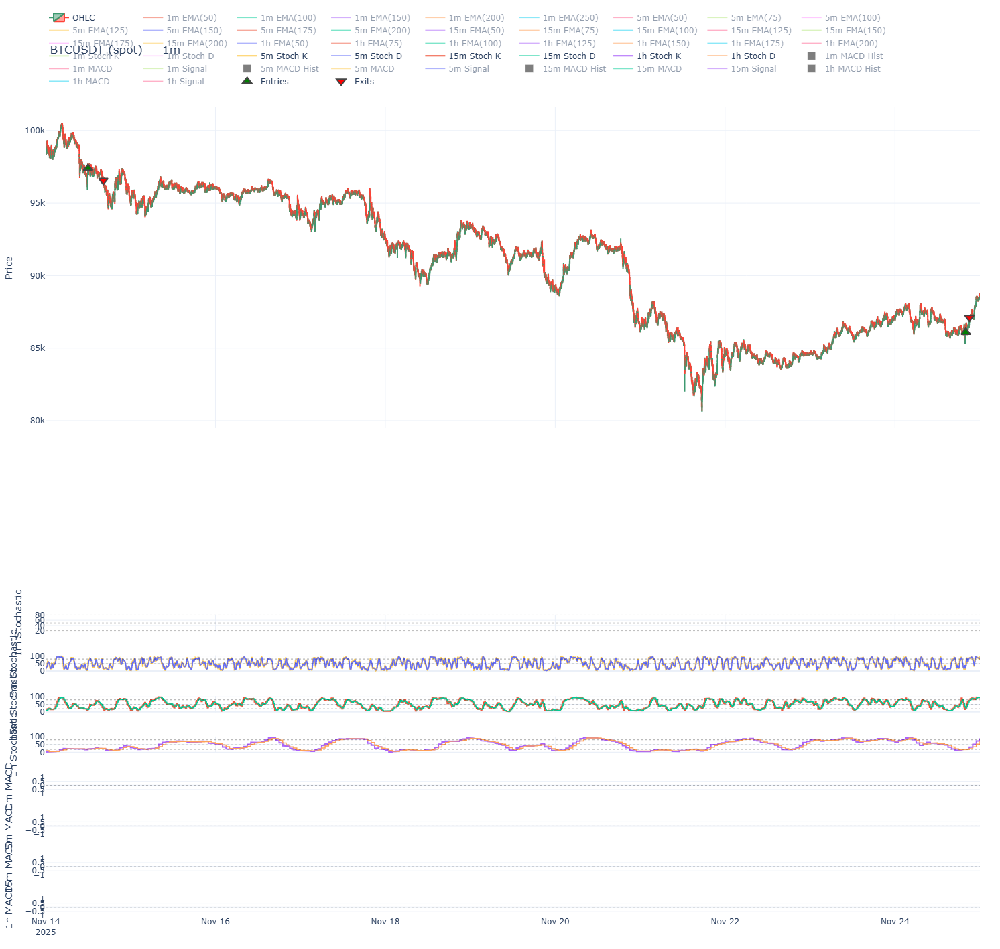

In [11]:
plot_simulation(
    df_raw=merged,
    symbol=symbol,
    interval="1m",
    market=market,
    trades=res.trades,
    ma_windows=[],
    indicators=plot_indicators,
    plot_cfg=PlotConfig(
        tz=tz,
        # date_from="2026-05-06",
        # date_to="2026-05-10",
        date_from="2025-11-14",
        date_to="2025-11-25",
        height=1400,
        width=1900,
    ),
)
